# CHAZ intensity

The [tracks notebook](tracks.ipynb) found that our ERA5 run reaches the US coast about as often as
the CHAZ team's, and that the two differ in how long their intensity members last. This notebook
looks at the intensity model around the globe and tests the options of `chaz` that change it:

- `--land fine` reads the land term at the storm's position on the 1/12° land mask rather than in
  the 2° cell it is in (section 2)
- `--intensity refit` refits the water and land regressions on our ERA5 environment along the
  observed tracks of 1981–2012 (sections 3 and 4)
- `--intensity refit-pi` and `--intensity refit-basin` also draw the random error from observed
  steps with similar ring PI, and then from steps in the same basin as well (section 4)

Every run covers 1981–2019 with 10 track realizations of 40 intensity members. They share their
random seeds, and so their seeds and tracks, and differ in intensity. The refit options read land
as `--land fine` does, since they are fit on it. 'shipped' is the run with the public code's
settings, the one the tracks notebook calls 'ours'.

`ocr.risks.hurricane.validate` compares each set with IBTrACS (USA_WIND) by the same rules:

- landfalls by country: the first hour on a country's land after an hour over sea, on the Natural
  Earth 1:10m countries at 1/12°, counted at the member's wind in that hour
- time at 64 and 96 kt: 6-hourly points over sea in the regions of `validate.REGIONS` and, for
  North Atlantic storms, in six North Atlantic regions
- storms first reaching 34 kt, by where they reach it
- US landfalls on the Atlantic and Gulf coasts, by the tracks notebook's rules

Rates are per year, and CHAZ's per intensity member. North Atlantic quantities (US landfalls and
time in the North Atlantic regions) are scaled so that each set's North Atlantic storm count
matches the observed one; the rest are not scaled. A storm belongs to the year of its first record.

All the sets make about as many storms as observed. The refit options bring more members to
34 kt: about 94 a year, against 85 with the shipped model and 86.5 observed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ocr.risks.hurricane import meanstd, refit, validate

RUN = 'TCGI_CRH_PI'
FINE = f'{RUN}-land-fine'
SOURCES = {
    'CHAZ team': 'chaz-team',
    'shipped': RUN,
    'fine land': FINE,
    'refit': f'{FINE}-intensity-refit',
    'refit-pi': f'{FINE}-intensity-refit-pi',
    'refit-basin': f'{FINE}-intensity-refit-basin',
    'refit-basin, fit 1981-1999': f'{FINE}-intensity-refit-basin-fit-1981-1999',
}
COLORS = {
    'CHAZ team': '#eb6834',
    'shipped': '#2a78d6',
    'fine land': '#8a5cc7',
    'refit': '#9c9a92',
    'refit-pi': '#e0a526',
    'refit-basin': '#1baf7a',
    'refit-basin, fit 1981-1999': '#0e6b4a',
}
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
tables = {'IBTrACS': validate.load('ibtracs')} | {k: validate.load(v) for k, v in SOURCES.items()}
YEARS = range(1981, 2020)
m = validate.metrics(tables, YEARS)


def vs_observed(rows, sources=None, digits=2):
    """IBTrACS per year, and each source over IBTrACS, for the rows IBTrACS has."""
    t = m.loc[rows, ['IBTrACS', *(sources or SOURCES)]]
    t = t[t['IBTrACS'] > 0]
    r = t.drop(columns='IBTrACS').div(t['IBTrACS'], axis=0)
    return pd.concat([t[['IBTrACS']].rename(columns={'IBTrACS': 'IBTrACS per yr'}), r], axis=1)


pd.DataFrame(
    {
        name: {
            'members per year': t['members'].mean(),
            'storms reaching 34 kt per member-year': t['TS formed global'].sum()
            / t['members'].sum(),
            'NA tropical storms per member-year': t['NA TS'].sum() / t['members'].sum(),
        }
        for name, t in tables.items()
    }
).T.style.format('{:.1f}')

,members per year,storms reaching 34 kt per member-year,NA tropical storms per member-year
IBTrACS,1.0,86.5,13.4
CHAZ team,400.0,88.0,12.7
shipped,400.0,85.0,13.2
fine land,400.0,85.7,13.4
refit,400.0,93.9,12.7
refit-pi,400.0,93.8,12.5
refit-basin,400.0,94.6,14.1
"refit-basin, fit 1981-1999",400.0,93.3,13.9


## 1. The shipped intensity model around the globe

With the shipped coefficients, our run spends too little time at hurricane and major strength
in the tropics and far too much at high latitudes. At 96 kt it has 0.27 of the observed time in the
Philippine Sea, 0.56 in the North Atlantic tropics and 0.35 in the Caribbean. North of 35°N in the
western Pacific it has 169 times the observed time at 96 kt, and north of 45°N in the North
Atlantic 65 times. The CHAZ team's set has the same pattern (0.40, 0.63 and 0.37; 76 and 16
times). Observed storms seldom stay that strong that far poleward, so the high-latitude ratios
rest on small observed numbers, and the score in section 5 leaves those regions out.

In [2]:
regions = [f'time {r} >= {t}' for t in (64, 96) for r in validate.REGIONS] + [
    f'NA time >= {t}: {r}' for t in (64, 96) for r in validate.NA_REGIONS
]
vs_observed(regions, ['CHAZ team', 'shipped']).style.format('{:.2f}').set_caption(
    '6-hourly points over sea at 64 and 96 kt, 1981-2019; North Atlantic rows scaled to the '
    'observed North Atlantic storm count'
)

,IBTrACS per yr,CHAZ team,shipped
time WP Philippine Sea >= 64,133.72,0.57,0.37
time WP South China Sea >= 64,51.23,0.48,0.57
time WP East China Sea/Japan >= 64,44.90,0.68,0.58
time WP north of 35N >= 64,3.95,4.34,7.51
time EP main >= 64,130.13,0.92,0.87
time EP north of 25N >= 64,0.87,4.83,12.69
time NI Bay of Bengal >= 64,8.15,0.98,1.53
time NI Arabian Sea >= 64,5.41,0.55,0.93
time SI west >= 64,78.13,1.04,0.80
time AU >= 64,43.67,1.16,1.35


At 64 kt our run makes 0.31 of the observed Philippine landfalls and 0.39 of
Taiwan's, and 1.7 times Australia's. Section 2 has US landfalls.

In [3]:
countries = [f'landfall {c} >= {t}' for t in (34, 64) for c in validate.COUNTRIES if c != 'USA']
vs_observed(countries, ['CHAZ team', 'shipped']).style.format('{:.2f}').set_caption(
    'Landfalls by country per year (first hour on its land after an hour over sea)'
)

,IBTrACS per yr,CHAZ team,shipped
landfall MEX >= 34,3.00,1.13,1.39
landfall CUB >= 34,0.69,0.79,1.09
landfall PHL >= 34,4.15,0.67,0.61
landfall CHN >= 34,5.44,0.82,0.81
landfall TWN >= 34,1.77,0.75,0.65
landfall JPN >= 34,3.67,1.07,1.00
landfall KOR >= 34,0.72,1.23,1.42
landfall VNM >= 34,2.62,0.79,1.01
landfall IND >= 34,1.74,0.52,0.79
landfall BGD >= 34,0.54,0.42,0.74


## 2. Land at the storm's position

The public code reads the land term from the 2° land mask cell the storm is in, so a storm over
open water in a cell the mask counts as land weakens as if it were over land. `--land fine` reads
the land term at the storm's own position on the tutorial's 1/12° mask.

In the North Atlantic this adds hurricane time in the Gulf (9.4 to 10.2 points a year, against
10.3 observed) and adds US hurricane landfalls only slightly (0.784 to 0.808 a year, against
1.308 observed). Its score gain over the shipped run is small (section 5). We keep it because the
refit options are fit on it.

The table also shows how far the shipped run is from observed US landfalls: 0.784 hurricane
landfalls a year against 1.308, and 0.104 in Georgia and the Carolinas against 0.308. The CHAZ
team's set makes fewer (0.575). Our runs also make about 0.35 landfalls a year on the US Pacific
coast, which no observed storm reached over these years, against 0.064 in the CHAZ team's set.

In [4]:
na_rows = (
    ['NA TS storms/yr', 'NA share peak >= 64 kt', 'NA share peak >= 96 kt']
    + [f'Atl+Gulf landfalls >= {t} kt' for t in (34, 64, 96)]
    + [f'{r} landfalls >= 64 kt' for r in ('TX-AL', 'FL', 'GA-Car', 'VA-ME')]
    + ['Pacific coast landfalls >= 34 kt']
    + [f'NA time >= {t}: {r}' for t in (64, 96) for r in validate.NA_REGIONS]
)
t = m.loc[na_rows, ['IBTrACS', 'CHAZ team', 'shipped', 'fine land']]
t.style.format('{:.3f}').set_caption(
    'North Atlantic per year, 1981-2019; landfalls and time over sea scaled to the observed '
    'North Atlantic storm count (the Pacific coast row too: IBTrACS has none there)'
)

,IBTrACS,CHAZ team,shipped,fine land
NA TS storms/yr,13.385,12.701,13.220,13.396
NA share peak >= 64 kt,0.506,0.449,0.460,0.466
NA share peak >= 96 kt,0.207,0.200,0.199,0.204
Atl+Gulf landfalls >= 34 kt,2.974,2.137,2.666,2.680
Atl+Gulf landfalls >= 64 kt,1.308,0.575,0.784,0.808
Atl+Gulf landfalls >= 96 kt,0.179,0.106,0.160,0.161
TX-AL landfalls >= 64 kt,0.538,0.226,0.357,0.365
FL landfalls >= 64 kt,0.385,0.202,0.277,0.286
GA-Car landfalls >= 64 kt,0.308,0.107,0.104,0.108
VA-ME landfalls >= 64 kt,0.077,0.040,0.046,0.049


## 3. The shipped regression's response to PI

CHAZ standardizes each predictor with a mean and standard deviation from `coefficient_meanstd.nc`
before applying the regression's coefficients. Fitting the water regression the authors' way on
the tutorial's own observed-track file (`bt_global_predictors.nc`) gives back the shipped
coefficients to within 0.04. But in that sample the PI-minus-wind predictor (`dPIwspd`) has a mean
of 85 kt and a standard deviation of 44 kt, and the shipped normalization has 30 and 70. The
coefficients were fit on one standardization and are read with another.

In [5]:
tutorial = refit.fit(refit.tutorial_env())
era5_env = refit.era5_env()
era5 = refit.fit(era5_env)
shipped = refit.shipped()
names = ['const', *meanstd.WATER]
pd.DataFrame(
    {
        'shipped': shipped['w']['params'],
        'refit on the tutorial file': tutorial['w']['params'],
        'mean, shipped normalization': shipped['w']['meanX'],
        'mean, tutorial file sample': tutorial['w']['meanX'],
        'sd, shipped normalization': shipped['w']['stdX'],
        'sd, tutorial file sample': tutorial['w']['stdX'],
    },
    index=names,
).style.format('{:.3f}').set_caption(
    'Water regression: standardized coefficients and the normalization each is read with'
)

,shipped,refit on the tutorial file,"mean, shipped normalization","mean, tutorial file sample","sd, shipped normalization","sd, tutorial file sample"
const,0.000,-0.000,0.000,0.000,0.000,0.000
StormMwspd,-0.155,-0.142,50.700,48.728,25.851,28.272
dVdt,0.484,0.459,1.437,1.621,9.730,8.863
trSpeed,0.051,0.046,4.899,3.996,2.851,2.327
dPIwspd,0.326,0.331,30.157,85.013,70.183,43.759
SHRD,-0.101,-0.102,8.791,8.378,5.948,5.757
rhMean,0.084,0.082,59.347,60.020,10.643,8.994
dPIwspd2,0.211,0.195,5835.035,9141.976,5217.420,6329.424
dPIwspd3,-0.454,-0.417,402117.096,1037520.869,781400.051,907492.061
dVdt2,0.032,0.012,96.740,81.184,223.298,186.872


Read that way, the regression responds less to PI. For a storm whose wind did not change over the
previous 12 hours, in a mean environment, a 140 kt storm under a ring PI of 40 kt loses 1.8 kt in
12 hours with the shipped files. The same fit read with its own normalization takes off 7.8 kt,
and the ERA5 refit 16.1 kt. At the high-PI end the shipped files give a 60 kt storm under a ring
PI of 190 kt a loss of 2.2 kt, where its own normalization gives a gain of 0.4 kt. A response this
weak keeps storms strong over cold water, which fits the high-latitude excess of section 1.

ring PI (kt)                              40    70    100  130  160  190
shipped                             60   -3.0  -1.8  -0.1  1.0  0.7 -2.2
                                    100  -4.8  -5.6  -4.7 -3.1 -1.7 -1.4
                                    140  -1.8  -6.4  -8.0 -7.6 -6.1 -4.5
tutorial fit, its own normalization 60   -5.4  -3.4  -1.2  0.7  1.5  0.4
                                    100  -8.3  -7.8  -6.1 -3.8 -1.7 -0.5
                                    140  -7.8 -10.0 -10.0 -8.6 -6.4 -4.2
ERA5 refit                          60   -5.6  -2.8  -0.4  1.1  1.4  0.2
                                    100 -11.2  -8.4  -5.5 -2.9 -1.1 -0.4
                                    140 -16.1 -13.9 -11.1 -8.2 -5.5 -3.4

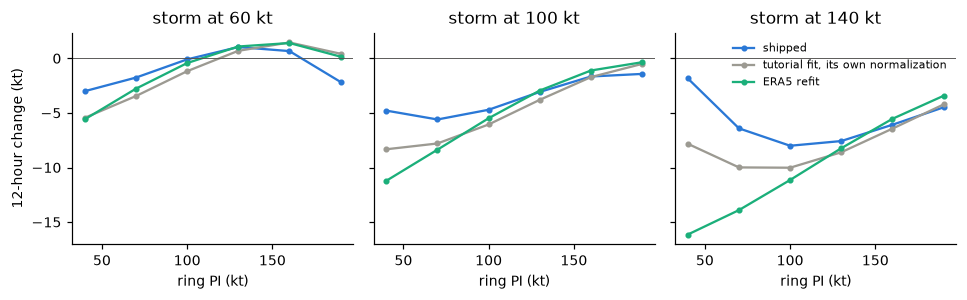

In [6]:
winds, pis = (60, 100, 140), (40, 70, 100, 130, 160, 190)
fits = {
    'shipped': shipped['w'],
    'tutorial fit, its own normalization': tutorial['w'],
    'ERA5 refit': era5['w'],
}
resp = pd.DataFrame(
    {
        (name, w): [
            refit.response(c['params'], c['meanX'], c['stdX'], c['meanY'], c['stdY'], w, p)
            for p in pis
        ]
        for name, c in fits.items()
        for w in winds
    },
    index=pd.Index(pis, name='ring PI (kt)'),
)
fig, axes = plt.subplots(1, len(winds), figsize=(9, 2.8), sharey=True)
for ax, w in zip(axes, winds):
    for name, color in zip(fits, ('#2a78d6', '#9c9a92', '#1baf7a')):
        ax.plot(pis, resp[(name, w)], color=color, label=name, marker='o', ms=3)
    ax.axhline(0, color='#52514e', lw=0.6)
    ax.set_title(f'storm at {w} kt')
    ax.set_xlabel('ring PI (kt)')
axes[0].set_ylabel('12-hour change (kt)')
axes[-1].legend(frameon=False, fontsize=7)
fig.tight_layout()
resp.T.round(1)

## 4. Refitting the regressions on ERA5

`ocr.risks.hurricane.refit` fits both regressions as the authors' script does
(`CHAZvBeta/tools/regression4.py`), on our ERA5 environment along the tutorial's observed tracks
of 1981–2012, and writes the normalization of its own sample. Land is read as `--land fine` reads
it; the tutorial file's fit uses its 300 km land mean. Water steps fit about as well as with the
tutorial file (R² 0.395 against 0.392), and land steps better (0.537 against 0.455).

In [7]:
pd.DataFrame(
    {
        (name, {'w': 'water', 'l': 'land'}[tag]): {
            'steps': f[tag]['n'],
            'R2': f[tag]['r2'],
            'rmse (kt)': f[tag]['rmse'],
        }
        for name, f in (('tutorial file', tutorial), ('ERA5', era5))
        for tag in 'wl'
    }
).style.format('{:.3f}')

CHAZ adds to each 12-hour step an error drawn from the regression's errors on observed steps that
start in the same 10 kt wind bin. Those errors also depend on PI. At 60–100 kt, steps in the top
third of ring PI gain 2.9–3.4 kt more than predicted, and gain more than 10 kt above the prediction
in 0.21–0.22 of steps, against 0.09 in the bottom third. `--intensity refit-pi` draws the error
from steps in the same wind bin and tercile of ring PI.

They depend on the basin too. At 64–96 kt over water, observed storms gain more than predicted in
the North Indian Ocean (+4.1 kt), the North Atlantic (+1.8) and the western Pacific (+1.6) than in
the Southern Hemisphere (+0.4) and the eastern Pacific (+0.3). `--intensity refit-basin` draws from
the steps of the same basin as well.

In [8]:
r = refit.residuals_by_pi(era5).loc['w']
r.style.format(
    {
        'n': '{:.0f}',
        'PI median': '{:.0f}',
        'mean': '{:+.1f}',
        'sd': '{:.1f}',
        'P(> +10 kt)': '{:.2f}',
    }
).set_caption(
    'ERA5 refit, water regression: observed minus predicted 12-hour change (kt), by starting '
    'wind and tercile of ring PI'
)

In [9]:
steps = refit.predictions(era5, era5_env, meanstd.YEARS)
s = steps[(steps['v0'] >= 64) & (steps['v0'] < 96)]
g = s.groupby(['regression', 'basin'])['residual']
pd.DataFrame({'steps': g.size(), 'mean (kt)': g.mean()}).unstack(0).style.format(
    {
        ('steps', 'w'): '{:.0f}',
        ('steps', 'l'): '{:.0f}',
        ('mean (kt)', 'w'): '{:+.1f}',
        ('mean (kt)', 'l'): '{:+.1f}',
    }
).set_caption('ERA5 refit: observed minus predicted 12-hour change at 64-96 kt, 1981-2012')

The refit alone lifts major time in the Philippine Sea from 0.27 to 0.48 of observed and cuts the
excess north of 35°N in the western Pacific (169 to 71 times observed at 96 kt). In the North
Atlantic it loses ground: hurricane time in the Gulf falls from 0.99 to 0.70 of observed, and US
hurricane landfalls from 0.62 to 0.51.

Of the three refits, refit-basin comes closest in the North Atlantic: US landfalls 0.97 of
observed, hurricane landfalls 0.63 and Gulf hurricane time 0.86. US major landfalls fall, from
0.89 with the shipped run to 0.63. In the western Pacific it brings major time in the Philippine
Sea to 0.82 and Philippine hurricane landfalls to 0.64. It overshoots in the Southern Hemisphere:
major time is 2.3 times observed in the South Pacific and 1.8 times in the Australian region, as
with refit-pi (2.5 and 2.0).

In [10]:
options = ['shipped', 'fine land', 'refit', 'refit-pi', 'refit-basin']
key_rows = (
    [f'Atl+Gulf landfalls >= {t} kt' for t in (34, 64, 96)]
    + ['NA share peak >= 64 kt', 'NA share peak >= 96 kt']
    + [f'NA time >= {t}: {r}' for t in (64, 96) for r in validate.NA_REGIONS]
    + [f'time {r} >= {t}' for t in (64, 96) for r in validate.REGIONS]
    + [f'landfall {c} >= 64' for c in ('PHL', 'CHN', 'TWN', 'JPN', 'VNM', 'MEX', 'AUS', 'IND')]
)
vs_observed(key_rows, options).style.format('{:.2f}').set_caption(
    'IBTrACS per year and each option over IBTrACS, 1981-2019'
)

,IBTrACS per yr,shipped,fine land,refit,refit-pi,refit-basin
Atl+Gulf landfalls >= 34 kt,2.97,0.90,0.90,0.91,0.88,0.97
Atl+Gulf landfalls >= 64 kt,1.31,0.60,0.62,0.51,0.50,0.63
Atl+Gulf landfalls >= 96 kt,0.18,0.89,0.90,0.52,0.56,0.63
NA share peak >= 64 kt,0.51,0.91,0.92,0.81,0.78,0.95
NA share peak >= 96 kt,0.21,0.96,0.99,0.83,0.83,0.97
NA time >= 64: Gulf,10.28,0.92,0.99,0.70,0.68,0.86
NA time >= 64: Caribbean,11.97,0.64,0.65,0.67,0.71,0.80
NA time >= 64: W Atlantic,29.31,0.53,0.54,0.55,0.57,0.67
NA time >= 64: MDR,18.23,0.56,0.56,0.64,0.67,0.77
NA time >= 64: Subtropical,23.87,0.69,0.68,0.61,0.56,0.87


## 5. Score and a test on years the fit did not see

`validate.score` puts these together as the mean |ln(set / IBTrACS)| over 41 metrics: US Atlantic
and Gulf landfalls at 34, 64 and 96 kt; the North Atlantic shares of storms peaking at 64 and
96 kt; time at 64 and 96 kt in five North Atlantic regions and nine others; and hurricane
landfalls in eight countries. High latitudes are left out. A set with none of something observed
counts as 0.05 of it. Lower is better. Over 2000–2019 refit-basin scores 0.329, the shipped run
0.455 and the CHAZ team's set 0.395.

In [11]:
PERIODS = {
    '1981-1999': range(1981, 2000),
    '2000-2019': range(2000, 2020),
    '2000-2012': range(2000, 2013),
    '2013-2019': range(2013, 2020),
}
scores = pd.DataFrame(
    {p: validate.score(validate.metrics(tables, ys)) for p, ys in PERIODS.items()}
)
scores.style.format('{:.3f}').set_caption(
    f'Mean |ln(source / IBTrACS)| over {len(validate.SCORED)} metrics (lower is better)'
)

,1981-1999,2000-2019,2000-2012,2013-2019
CHAZ team,0.483,0.395,0.432,0.447
shipped,0.484,0.455,0.501,0.457
fine land,0.469,0.441,0.485,0.456
refit,0.461,0.391,0.433,0.389
refit-pi,0.486,0.378,0.455,0.365
refit-basin,0.433,0.329,0.426,0.342
"refit-basin, fit 1981-1999",0.424,0.321,0.423,0.317


The refits are fit on the observed tracks of 1981–2012, so their scores over those years are
partly in sample. `--fit 1981-1999` fits refit-basin on 1981–1999 only. It scores 0.321 over
2000–2019, against 0.329 for the fit on all years, and 0.317 against 0.342 over 2013–2019, which
neither fit saw. Over 2000–2019 it improves on `--land fine` alone by 0.108, and 90% of resamples
of the years put the gain between 0.044 and 0.155. `--land fine` improves on the shipped run by
0.011 (90% between 0.000 and 0.020). The gains of the refit hold on years it was not fit on.

Two inputs still see the later years: the seeding ratio counts the observed storms of 1981–2005,
and the North Atlantic quantities are scaled to each period's observed storm count. Neither
depends on intensity.

In [12]:
pairs = [
    ('refit-basin, fit 1981-1999', 'fine land'),
    ('refit-basin, fit 1981-1999', 'refit-basin'),
    ('refit-basin', 'fine land'),
    ('fine land', 'shipped'),
]
rows = {}
for p in ('2000-2019', '2013-2019'):
    b = validate.bootstrap(tables, PERIODS[p], n=2000, seed=0)
    for a, c in pairs:
        d = b[a] - b[c]
        rows[(p, f'{a} − {c}')] = {
            'median': d.median(),
            '5%': d.quantile(0.05),
            '95%': d.quantile(0.95),
            'P(< 0)': (d < 0).mean(),
        }
pd.DataFrame(rows).T.style.format('{:+.3f}').set_caption(
    'Paired score differences over 2,000 resamples of whole years (negative: the first scores better)'
)

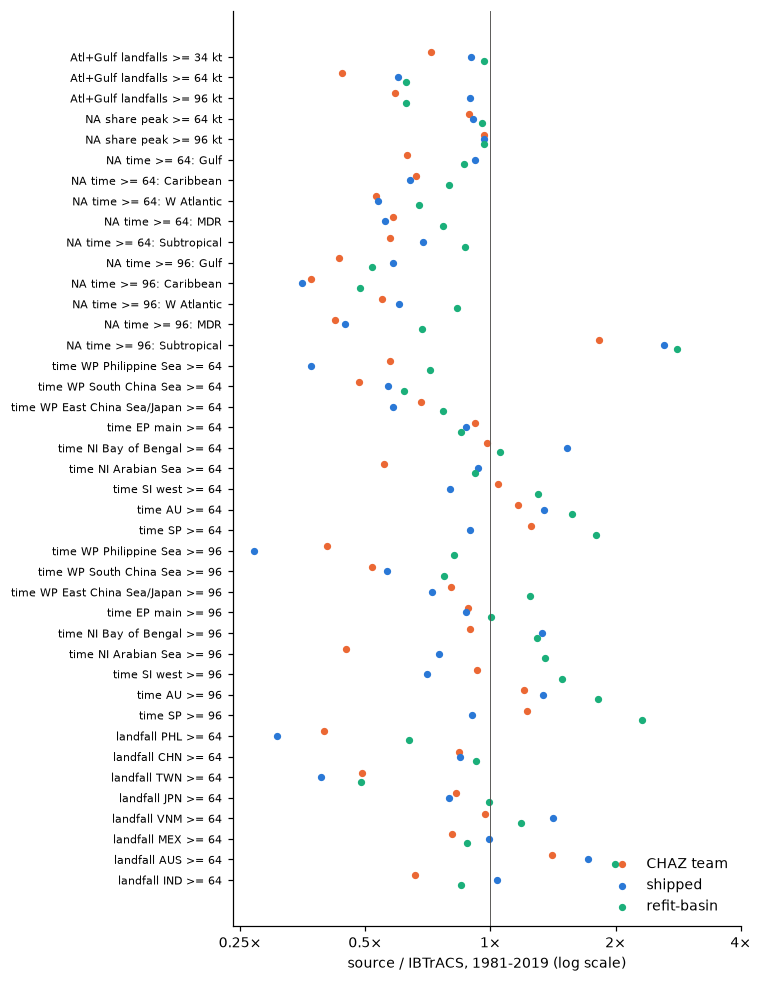

In [13]:
t = validate.metrics(tables, YEARS).loc[validate.SCORED]
lr = np.log(t.drop(columns='IBTrACS').div(t['IBTrACS'], axis=0).clip(lower=validate.FLOOR))
show = ['CHAZ team', 'shipped', 'refit-basin']
fig, ax = plt.subplots(figsize=(7, 9))
y = np.arange(len(lr))
for k, name in enumerate(show):
    ax.scatter(lr[name], y + (k - 1) * 0.22, s=14, color=COLORS[name], label=name)
ax.axvline(0, color='#52514e', lw=0.6)
ax.set_yticks(y, lr.index, fontsize=7)
ax.invert_yaxis()
ticks = [0.25, 0.5, 1, 2, 4]
ax.set_xticks(np.log(ticks), [f'{v:g}×' for v in ticks])
ax.set_xlabel('source / IBTrACS, 1981-2019 (log scale)')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()

## 6. Misses after the refit

Some misses survive every option:

- The Southern Hemisphere overshoot starts at genesis. The shipped run already has 1.45 times the
  observed number of storms reaching 34 kt in the South Pacific; refit-basin, which brings more
  members to 34 kt, has 2.11 times.
- High latitudes. Fewer storms first reach 34 kt there with refit-basin (south of 30°S, 40 to 21
  times observed; north of 35°N in the western Pacific, 12.5 to 4.9 times), but hurricane time
  stays 12 and 3.5 times observed.
- North Atlantic majors: 2.8 times the observed time in the subtropics and 0.52 in the Gulf.
- Taiwan's hurricane landfalls, at 0.49 of observed.

In [14]:
left = (
    [f'TS formed {r}' for r in ('SP', 'AU', 'SI west', 'SH south of 30S', 'WP north of 35N')]
    + ['time SP >= 96', 'time AU >= 96', 'time SH south of 30S >= 64', 'time WP north of 35N >= 64']
    + ['NA time >= 96: Subtropical', 'NA time >= 96: north of 45N', 'NA time >= 96: Gulf']
    + ['landfall TWN >= 64', 'Atl+Gulf landfalls >= 96 kt']
)
vs_observed(left, ['shipped', 'refit-basin']).style.format('{:.2f}')

,IBTrACS per yr,shipped,refit-basin
TS formed SP,6.18,1.45,2.11
TS formed AU,10.00,1.11,1.29
TS formed SI west,8.95,1.10,1.35
TS formed SH south of 30S,0.03,39.70,20.75
TS formed WP north of 35N,0.08,12.51,4.91
time SP >= 96,13.00,0.90,2.32
time AU >= 96,12.69,1.34,1.81
time SH south of 30S >= 64,0.85,30.82,12.39
time WP north of 35N >= 64,3.95,7.51,3.47
NA time >= 96: Subtropical,1.69,2.62,2.81


## Summary

| | proposed | evidence |
| --- | --- | --- |
| land term | `--land fine`: land at the storm's position on the 1/12° mask | section 2; the refits are fit on it |
| intensity | `--intensity refit-basin`: regressions refit on ERA5 along the observed tracks of 1981–2012, random error drawn by basin, wind and ring PI | sections 4 and 5: the best score of the options, which holds on years the fit did not see |

Open:

- **A regional calibration.** No option here fixes the Southern Hemisphere overshoot, US
  hurricane landfalls (0.63 of observed with refit-basin) or the high latitudes. Genesis comes
  first: `chaz --genesis calibrated` scales TCGI by region, but its map was fit on an earlier run
  and needs refitting on the configuration chosen here. A regional adjustment of intensity would
  come after it.
- **Climate-model runs.** The refits are fit on ERA5 and run only on ERA5 forcing. A climate model
  needs its own normalization of the refit regressions, as it does for the shipped ones
  ([cmip.ipynb](cmip.ipynb)).